# Part 1: Probability Distributions

## Introduction
In this project, we will use the Galton dataset to compare mothers' and children's heights. We will treat the data as a mixture of two Gaussian distributions without knowing the group labels.

## Objective
We will implement the Expectation-Maximization (EM) algorithm from scratch in Python to estimate each group's mean, variance, and mixing proportion.

## Method
1. Load and explore the dataset.
2. Initialize the parameters of two Gaussian distributions.
3. Apply the E-step and M-step iteratively.
4. Record the parameters and log-likelihood for the first two iterations.
5. Test the model using a new height and display its posterior probabilities.

## Why EM?
We should not simply split the data at the global mean because this creates an arbitrary division and ignores the distributions' spread and uncertainty. EM estimates the parameters iteratively using the probability that each observation belongs to each group.

In [ ]:
"""
Part 1: EM algorithm (from scratch) - Mothers vs Children heights.
Libraries: numpy, matplotlib, and the built-in csv module.
"""
import csv
import numpy as np
import matplotlib.pyplot as plt

DATA_FILE = "GaltonFamilies.csv"
TEST_HEIGHT = 67.0
UNIT = "in"

# ---------------------------------------------------------------- 1. Data
def load_data(filename):   
    heights, truth, seen = [], [], set()
    with open(filename, newline="") as f:
        for row in csv.DictReader(f):
            if row["family"] not in seen:                 
                seen.add(row["family"])
                heights.append(float(row["mother"]))
                truth.append("Mother")
            heights.append(float(row["childHeight"]))
            truth.append("Son" if row["gender"] == "male" else "Daughter")
    return np.array(heights), np.array(truth)


In [ ]:
# ---------------------------------------------------------------- 2. Calculations
def gaussian(x, mean, var):
    """Bell curve height at x."""
    return np.exp(-(x - mean) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)


def e_step(x, mean, var, pi):
    """E-step: probability (responsibility) that each height belongs to each group.
    Also returns the log-likelihood (how well the model fits the data)."""
    a = pi[0] * gaussian (x, mean[0], var[0])
    b = pi[1] * gaussian (x, mean[1], var[1])
    total = a + b
    return np.column_stack((a / total, b / total)), np.sum(np.log(total))

def m_step(x, r):
    """M-step: re-estimate mean, variance, weight using the responsibilities."""
    n = r.sum(axis=0)
    mean = (r * x[:, None]).sum(axis=0) / n
    var = (r * (x[:, None] - mean) ** 2).sum(axis=0) / n
    return mean, var, n / len(x)


In [ ]:
def mean_split(x):
    """The naive idea: cut at the global mean and average each pile. Used as iteration 0."""
    low, high = x[x < x.mean()], x[x >= x.mean()]
    mean = np.array([low.mean(), high.mean()])
    var = np.array([low.var(), high.var()])
    pi = np.array([len(low), len(high)]) / len (x)
    return mean, var, pi

def run_em(x, tol=1e-6, max_iter=2000):
    mean, var, pi = mean_split(x)
    history = []
    for i in range(max_iter + 1):
        r, ll = e_step(x, mean, var, pi)
        history.append((i, mean, var, pi, ll))
        if i > 0 and ll - history[-2][4] < tol:
            break
        mean, var, pi = m_step(x, r)
    return history

def classify(h, mean, var, pi):
    """Bayes' theorem: P(group | height)."""
    a = pi[0] * gaussian(h, mean[0], var[0])
    b = pi[1] * gaussian(h, mean[1], var[1])
    return a / (a + b), b / (a + b)

# ---------------------------------------------------------------- 3. Plots
def plot_mixture(ax, x, mean, var, pi, title):
    ax.hist(x, bins=np.arange(x.min() - 0.25, x.max() + 1, 1), density=True,
            color="#cfd8dc", edgecolor="white")
    grid = np.linspace(x.min() - 3, x.max() + 3, 400)
    for k, color in enumerate(["#2a9d8f", "#e76f51"]):
        curve = pi[k] * gaussian(grid, mean[k], var[k])
        ax.plot(grid, curve, color=color, lw=2,
                label=f"Group {k+1}: mean={mean[k]:.2f}, weight={pi[k]:.2f}")
    ax.set(title=title, xlabel="Height (inches)", ylabel="Density")
    ax.legend(fontsize=8)


Total heights: 1139 (mothers: 205, children: 934)
Global mean: 66.252 in

TRACKING TABLE (Group 1 = lower heights, Group 2 = higher heights)
Iter |  Mean1  |  Mean2  |  Var1  |  Var2  |  Pi1  |  Pi2  | Log-Likelihood
   0 | 63.5759 | 69.4718 | 3.4783 | 4.5477 | 0.5461 | 0.4539 | -3061.6755
   1 | 63.7280 | 69.3527 | 4.1811 | 5.4578 | 0.5513 | 0.4487 | -3042.7613
   2 | 63.8104 | 69.2956 | 4.5346 | 5.9142 | 0.5549 | 0.4451 | -3038.6870

EM converged after 331 iterations (log-likelihood stopped improving).
Group 1: mean=64.30  var=5.79  weight=0.64
Group 2: mean=69.79  var=5.47  weight=0.36

TEST HEIGHT: 67.0 in (67.00 in)
  P(Group 1, lower  / mother-like) = 0.655637
  P(Group 2, higher / child-like)  = 0.344363

WHAT DID EM LEARN? (hidden labels revealed)
True group |  in Group 1 |  in Group 2
Mother     |         195 |          10
Daughter   |         421 |          32
Son        |         124 |         357
-> EM mostly separates women (mothers + daughters) from men (sons).


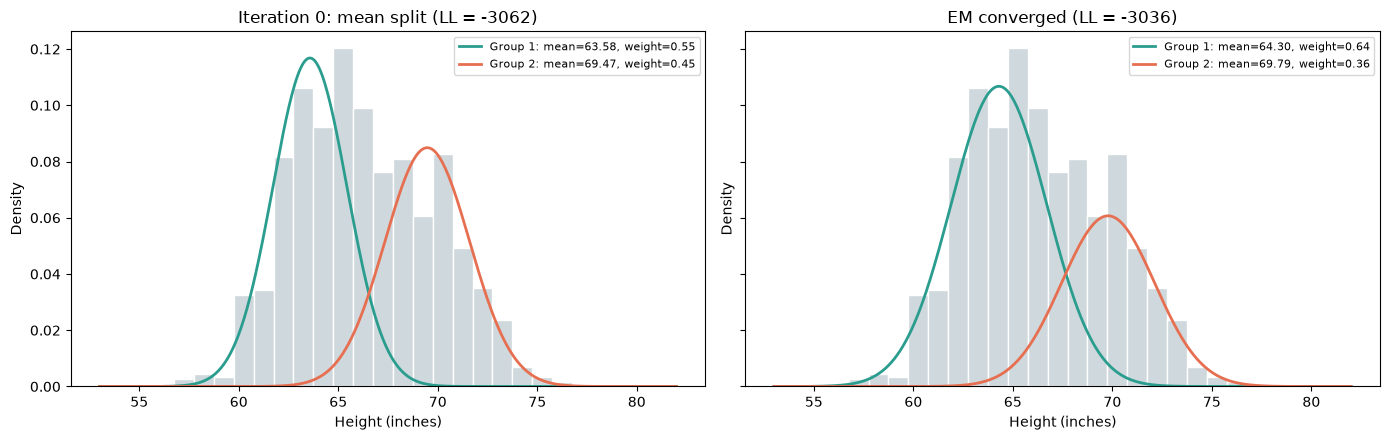

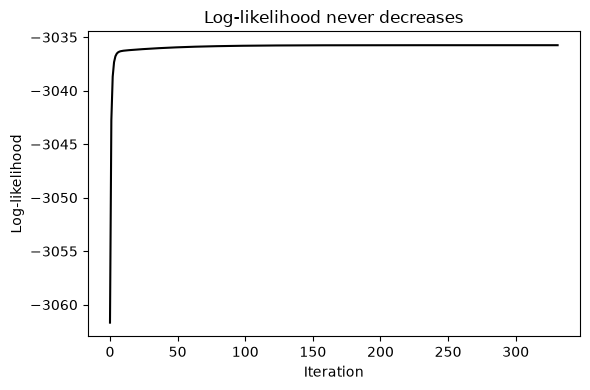

In [ ]:
# ---------------------------------------------------------------- 4. Executing
def main():
    x, truth = load_data(DATA_FILE)
    print(f"Total heights: {len(x)} "
          f"(mothers: {np.sum(truth == 'Mother')}, children: {np.sum(truth != 'Mother')})")
    print(f"Global mean: {x.mean():.3f} in\n")

    history = run_em(x)

    # --- Required tracking table: initial state + first two iterations
    print("TRACKING TABLE (Group 1 = lower heights, Group 2 = higher heights)")
    print("Iter |  Mean1  |  Mean2  |  Var1  |  Var2  |  Pi1  |  Pi2  | Log-Likelihood")
    for i, m, v, p, ll in history[:3]:
        print(f"{i:4d} | {m[0]:7.4f} | {m[1]:7.4f} | {v[0]:6.4f} | {v[1]:6.4f} "
              f"| {p[0]:.4f} | {p[1]:.4f} | {ll:.4f}")

    last, mean, var, pi, ll = history[-1]
    print(f"\nEM converged after {last} iterations (log-likelihood stopped improving).")
    print(f"Group 1: mean={mean[0]:.2f}  var={var[0]:.2f}  weight={pi[0]:.2f}")
    print(f"Group 2: mean={mean[1]:.2f}  var={var[1]:.2f}  weight={pi[1]:.2f}")

    # --- Classify the test height
    h = TEST_HEIGHT / 2.54 if UNIT == "cm" else TEST_HEIGHT
    p1, p2 = classify(h, mean, var, pi)
    print(f"\nTEST HEIGHT: {TEST_HEIGHT} {UNIT} ({h:.2f} in)")
    print(f"  P(Group 1, lower  / mother-like) = {p1:.6f}")
    print(f"  P(Group 2, higher / child-like)  = {p2:.6f}")

    # --- What did EM really learn? Reveal the hidden labels.
    r, _ = e_step(x, mean, var, pi)
    group2 = r[:, 1] > 0.5
    print("\nWHAT DID EM LEARN? (hidden labels revealed)")
    print("True group |  in Group 1 |  in Group 2")
    for g in ("Mother", "Daughter", "Son"):
        mask = truth == g
        print(f"{g:10s} | {np.sum(~group2 & mask):11d} | {np.sum(group2 & mask):11d}")
    print("-> EM mostly separates women (mothers + daughters) from men (sons).")

    # --- Graphs: mean split vs EM
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    _, m0, v0, p0, ll0 = history[0]
    plot_mixture(axes[0], x, m0, v0, p0, f"Iteration 0: mean split (LL = {ll0:.0f})")
    plot_mixture(axes[1], x, mean, var, pi, f"EM converged (LL = {ll:.0f})")
    fig.tight_layout()
    fig.savefig("mean_split_vs_em.png", dpi=150)

    fig2, ax2 = plt.subplots(figsize=(6, 4))
    ax2.plot([h_[0] for h_ in history], [h_[4] for h_ in history], color="k")
    ax2.set(title="Log-likelihood never decreases", xlabel="Iteration", ylabel="Log-likelihood")
    fig2.tight_layout()
    fig2.savefig("log_likelihood.png", dpi=150)
    plt.show()
if __name__ == "__main__":
    main()